In [1]:

from pathlib import Path
import rasterio
import numpy as np
import torch

project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

test_file = project_dir / "data" / "raw" / "Esch_Belval_June2025_Test.tif"

with rasterio.open(test_file) as src:
    data = src.read()
    print("Shape:", data.shape)
    print("Resolution:", src.res)
    print("CRS:", src.crs)

sar = data[:2]
labels = data[2]

valid = np.isfinite(data).all(axis=0) & (labels >= 0) & (labels <= 8)

print("Valid labeled pixels:", int(valid.sum()))
print("Classes:", np.unique(labels[valid]).astype(int))
print("GPU available:", torch.cuda.is_available())


Shape: (3, 521, 519)
Resolution: (10.0, 10.0)
CRS: EPSG:32632
Valid labeled pixels: 184905
Classes: [0 1 2 4 5 6 7]
GPU available: True


In [2]:

import torch.nn as nn
import torch.nn.functional as F

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = DoubleConv(2, 16)
        self.enc2 = DoubleConv(16, 32)
        self.enc3 = DoubleConv(32, 64)
        self.bottleneck = DoubleConv(64, 128)
        self.pool = nn.MaxPool2d(2)
        self.dec3 = DoubleConv(192, 64)
        self.dec2 = DoubleConv(96, 32)
        self.dec1 = DoubleConv(48, 16)
        self.output = nn.Conv2d(16, 5, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottleneck(self.pool(e3))

        d3 = F.interpolate(b, size=e3.shape[2:],
                           mode="bilinear", align_corners=False)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = F.interpolate(d3, size=e2.shape[2:],
                           mode="bilinear", align_corners=False)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = F.interpolate(d2, size=e1.shape[2:],
                           mode="bilinear", align_corners=False)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output(d1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_v2 = UNet().to(device)

weights_path = project_dir / "models" / "best_unet_v2.pth"
model_v2.load_state_dict(
    torch.load(weights_path, map_location=device, weights_only=True)
)
model_v2.eval()

print("Model loaded successfully!")
print("Device:", device)
print("Parameters:", sum(p.numel() for p in model_v2.parameters()))


Model loaded successfully!
Device: cuda
Parameters: 488629


In [3]:

# Independent test inference — Sentinel-1 VV/VH only

lower = np.array([-30, -35], dtype=np.float32)[:, None, None]
upper = np.array([5, 0], dtype=np.float32)[:, None, None]

sar_valid = np.isfinite(sar).all(axis=0)

x = np.nan_to_num(
    (np.clip(sar, lower, upper) - lower) / (upper - lower),
    nan=0.0, posinf=0.0, neginf=0.0
).astype(np.float32)

height, width = x.shape[1:]
prediction = np.zeros((height, width), dtype=np.uint8)

model_v2.eval()

with torch.inference_mode():
    for row in range(0, height, 128):
        for col in range(0, width, 128):

            tile = x[:, row:row+128, col:col+128]
            h, w = tile.shape[1:]

            padded = np.zeros((2, 128, 128), dtype=np.float32)
            padded[:, :h, :w] = tile

            tensor = torch.from_numpy(
                padded[None]
            ).to(device)

            pred = model_v2(tensor).argmax(1)
            prediction[row:row+h, col:col+w] = (
                pred[0, :h, :w].cpu().numpy()
            )

prediction[~sar_valid] = 255

print("Prediction shape:", prediction.shape)
print("Predicted classes:", np.unique(prediction))
print("Prediction generated successfully!")


Prediction shape: (521, 519)
Predicted classes: [  0   1   2   3   4 255]
Prediction generated successfully!


In [4]:

# Independent test: compare predictions with reference labels

class_mapping = {
    0: 0,  # Water
    1: 1,  # Trees
    2: 2,  # Grass
    4: 3,  # Crops
    6: 4   # Built-up
}

reference = np.full(labels.shape, 255, dtype=np.uint8)

for original, mapped in class_mapping.items():
    reference[valid & (labels == original)] = mapped

# Exclude invalid and ignored pixels
mask = (reference != 255) & (prediction != 255)

cm = np.bincount(
    reference[mask].astype(int) * 5 +
    prediction[mask].astype(int),
    minlength=25
).reshape(5, 5)

tp = np.diag(cm)
actual = cm.sum(axis=1)
predicted = cm.sum(axis=0)

iou = tp / np.maximum(actual + predicted - tp, 1)
f1 = 2 * tp / np.maximum(actual + predicted, 1)
accuracy = tp.sum() / max(cm.sum(), 1)

print(f"Test pixels: {mask.sum():,}")
print(f"Overall Accuracy: {accuracy*100:.2f}%")
print(f"Mean IoU: {iou.mean()*100:.2f}%")
print(f"Macro F1: {f1.mean()*100:.2f}%")

names = ["Water", "Trees", "Grass", "Crops", "Built-up"]

for name, a, b in zip(names, iou, f1):
    print(f"{name}: IoU={a*100:.2f}% | F1={b*100:.2f}%")


Test pixels: 181,543
Overall Accuracy: 79.90%
Mean IoU: 38.72%
Macro F1: 49.45%
Water: IoU=7.04% | F1=13.16%
Trees: IoU=64.35% | F1=78.31%
Grass: IoU=25.55% | F1=40.70%
Crops: IoU=14.01% | F1=24.58%
Built-up: IoU=82.63% | F1=90.49%


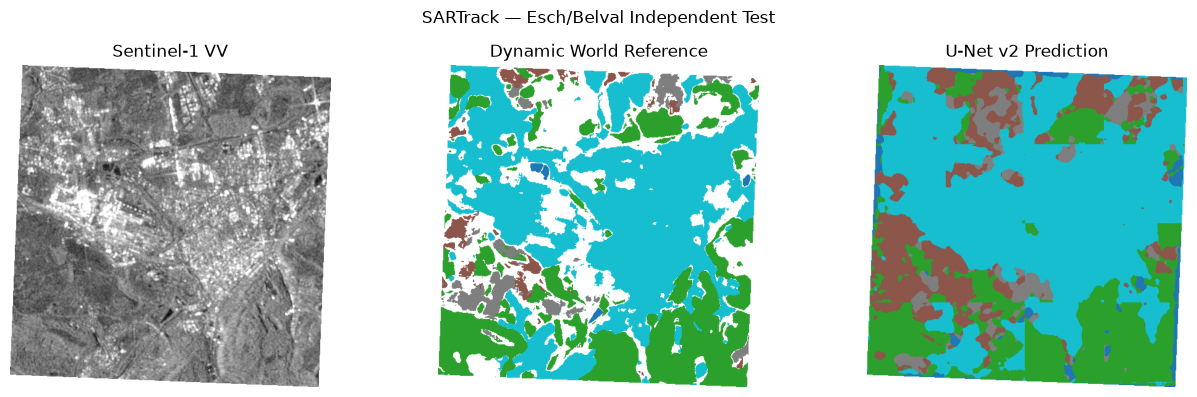

In [5]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

sar_display = np.ma.masked_where(~sar_valid, x[0])
reference_display = np.ma.masked_where(reference == 255, reference)
prediction_display = np.ma.masked_where(prediction == 255, prediction)

axes[0].imshow(sar_display, cmap="gray")
axes[0].set_title("Sentinel-1 VV")

axes[1].imshow(reference_display, cmap="tab10", vmin=0, vmax=4)
axes[1].set_title("Dynamic World Reference")

axes[2].imshow(prediction_display, cmap="tab10", vmin=0, vmax=4)
axes[2].set_title("U-Net v2 Prediction")

for ax in axes:
    ax.axis("off")

plt.suptitle("SARTrack — Esch/Belval Independent Test")
plt.tight_layout()

model_dir = project_dir / "models"
plt.savefig(model_dir / "esch_belval_test_prediction.png", dpi=200)
plt.show()
